Objective: Hospital readmissions are costly and often preventable. Predicting which patients are at higher risk of readmission allows healthcare organizations to intervene early, improving patient outcomes and reducing systemic costs. In this project, we will build, evaluate, and interpret a binary classification model to predict readmission risk using de-identified clinical data.

1. Import Libraries

What this code does:
Before we begin, we need to import our "toolkit." We bring in pandas for handling our data tables, matplotlib and seaborn for creating visual charts, and specific modules from scikit-learn to build, train, and evaluate our predictive model.

In [1]:
# Core data manipulation
import pandas as pd
import numpy as np

# Visualization libraries for clinical reporting
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning toolkit
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score

# Ensure our plots show up directly in the notebook
%matplotlib inline

Code Pattern: import [library] as [alias] is the standard Python pattern for loading necessary external packages before starting any data analysis.

2. Load Healthcare Dataset

What this code does:
We load our de-identified patient data into a Pandas DataFrame, which acts like a highly programmable Excel spreadsheet. Here, we are using the patient_data2.csv file, which simulates real-world inputs to a readmission risk model.

In [2]:
# Load the dataset into a pandas DataFrame
# We reference the file verbatim as requested
dataset_path = 'patient_data2.csv'
df = pd.read_csv(dataset_path)

# Display a success message
print(f"Successfully loaded the dataset from {dataset_path}!")

Successfully loaded the dataset from patient_data2.csv!


Code Pattern: pd.read_csv('filename.csv') is the universal starting point for loading flat-file datasets into a machine learning workflow.

3. Explore the Dataset

What this code does:
We inspect the first few rows of our data and check its overall structure (data types, row counts). Reviewing data is critical before modeling to ensure clinical relevance and trust in predictions

In [3]:
# Display the first 5 rows to understand the feature layout
display(df.head())

# Print a technical summary of the data
print("\nDataset Structure Summary:")
df.info()

,avg_glucose,encounter_count,has_diabetes,has_hypertension,readmitted
0,128.2,1,1,0,0
1,147.6,4,0,0,1
2,150.1,5,0,1,1
3,136.8,3,0,1,1
4,116.8,1,1,1,1



Dataset Structure Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   avg_glucose       2000 non-null   float64
 1   encounter_count   2000 non-null   int64  
 2   has_diabetes      2000 non-null   int64  
 3   has_hypertension  2000 non-null   int64  
 4   readmitted        2000 non-null   int64  
dtypes: float64(1), int64(4)
memory usage: 78.3 KB


Code Pattern: Always use .head() and .info() immediately after loading data to verify columns, detect data types, and check for glaring structural issues.

4. Handle Missing Values

What this code does:
Real-world clinical data is messy and often missing values. This step checks for missing data and fills them in. For numerical lab values, we fill missing spots with the median (to avoid outlier skewing). For categorical data, we fill them with "Unknown".

In [4]:
# Check for missing values in the dataset
missing_counts = df.isnull().sum()
print("Missing values per column:\n", missing_counts[missing_counts > 0])

# Impute missing numerical data with the median
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col] = df[col].fillna(df[col].median())

# Impute missing categorical data with a placeholder
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].fillna('Unknown')

Missing values per column:
 Series([], dtype: int64)


Code Pattern: .fillna() combined with .select_dtypes() allows you to programmatically clean entire classes of data (e.g., all numbers, all text) without hardcoding column names.

5. Select Features (X) and Target (y)

What this code does:
Machine learning models require a strict separation between the "clues" (features) and the "answer" (target). We separate our input features into X and our binary readmission label into y. Clear separation avoids accidental data leakage.

In [5]:
# The target variable 'readmitted' is what we want to predict
# We drop it from the feature set (X) and isolate it as the target (y)
X = df.drop(columns=["readmitted"])
y = df["readmitted"]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (2000, 4)
Target shape: (2000,)


Code Pattern: X = df.drop(columns=['target']) and y = df['target'] is the industry-standard way to isolate dependent and independent variables.

6. Encode Categorical Variables

What this code does:
Algorithms only understand numbers. If our dataset contains text features (like Gender or Admission Type), we must convert them into binary numeric columns using a process called "One-Hot Encoding."

In [6]:
# Convert categorical text variables into binary (0 or 1) numeric columns
X_encoded = pd.get_dummies(X, drop_first=True)

print(f"New feature shape after encoding: {X_encoded.shape}")

New feature shape after encoding: (2000, 4)


Code Pattern: pd.get_dummies(df, drop_first=True) quickly translates string categories into algorithmic-friendly numbers, dropping the first column to prevent multicollinearity.

7. Split into Training and Testing SetsWhat this code does:
We must hide a portion of our data from the model during training so we can test it fairly later. We divide the data: 75% for studying (training) and 25% for the final exam (testing). Testing on unseen data reflects real-world performance.  

In [7]:
# Split data into random train and test subsets
# test_size=0.25 reserves 25% of the data for testing
# random_state=42 ensures we get the exact same split every time we run the code
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.25, random_state=42
)

print(f"Training data size: {X_train.shape[0]} patients")
print(f"Testing data size: {X_test.shape[0]} patients")

Training data size: 1500 patients
Testing data size: 500 patients


Code Pattern: train_test_split(X, y, test_size, random_state) is the mandatory safeguard against "overfitting" (a model memorizing data instead of learning patterns).

8. Train a Regularized Logistic Regression Model

What this code does:
We initialize and train our logistic regression classifier. Here, we apply L2 Regularization (Ridge) using the C parameter. In clinical datasets, a model might accidentally memorize random noise (e.g., assuming a specific rare blood pressure always means readmission just because of one patient). Regularization mathematically penalizes the model for relying too heavily on any single feature, forcing it to look for broader, more generalizable clinical patterns.

In [8]:
# Initialize the model algorithm with Regularization
# 'penalty=l2' applies Ridge regularization.
# 'C=0.1' determines the strength of the regularization (smaller values = stronger penalty for complexity)
model = LogisticRegression(penalty='l2', C=0.1, max_iter=1000)

# Train ("fit") the regularized model on the training data
model.fit(X_train, y_train)

print("Model training (with L2 Regularization) complete!")

Model training (with L2 Regularization) complete!


Code Pattern: The C parameter in scikit-learn's LogisticRegression is the inverse of regularization strength. C=1.0 is default; lowering it (e.g., 0.1 or 0.01) forces the model to be simpler and less prone to overfitting.

9. Predict Readmission Risk

What this code does:
We ask our trained model to look at the hidden testing data (X_test) and guess whether each patient will be readmitted. Predictions enable proactive clinical interventions

In [9]:
# Generate binary predictions (0 = No Readmission, 1 = Readmission)
y_pred = model.predict(X_test)

# Generate probability scores (confidence level of the prediction)
y_prob = model.predict_proba(X_test)[:, 1]

print("Predictions generated for the test set.")

Predictions generated for the test set.


Code Pattern: model.predict() generates hard labels, while model.predict_proba() generates the percentage likelihood, which is often more useful in healthcare triaging.

10. Evaluate the Model

What this code does:
We grade the model's performance. Basic metrics provide initial insight. Evaluation helps balance missed readmissions (false negatives) against false alarms (false positives). We will look at Accuracy, the Confusion Matrix, the Classification Report, and the ROC Curve.

Accuracy: 89.20%



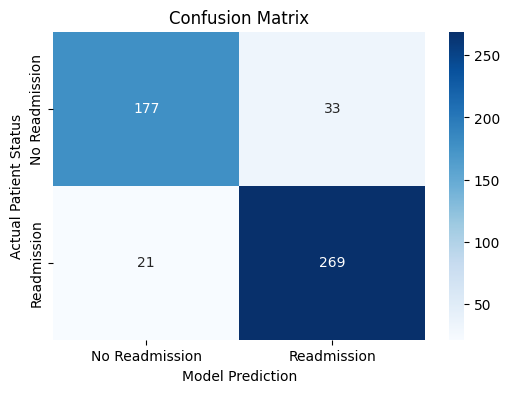

Classification Report:

              precision    recall  f1-score   support

           0       0.89      0.84      0.87       210
           1       0.89      0.93      0.91       290

    accuracy                           0.89       500
   macro avg       0.89      0.89      0.89       500
weighted avg       0.89      0.89      0.89       500



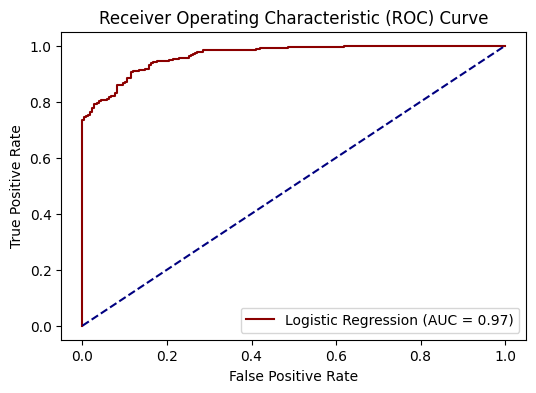

In [10]:
# 1. Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%\n")

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Readmission', 'Readmission'], yticklabels=['No Readmission', 'Readmission'])
plt.ylabel('Actual Patient Status')
plt.xlabel('Model Prediction')
plt.title('Confusion Matrix')
plt.show()

# 3. Classification Report
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

# 4. ROC Curve & AUC
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.2f})', color='darkred')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

Code Pattern: Wrapping model metrics (Accuracy, Matrix, ROC) into a single evaluation block is a standard workflow for communicating model viability to stakeholders.

11.. Model Calibration: Ensuring Trustworthy Probabilities

What this code does:
In healthcare, doctors use the probability score to triage patients (e.g., 85% risk vs. 51% risk). Calibration checks if our model's confidence matches reality. If the model predicts a 70% risk of readmission for a group of patients, exactly 70% of those patients should actually be readmitted. We use a Calibration Curve to visualize how close our predicted probabilities are to the true clinical outcomes.

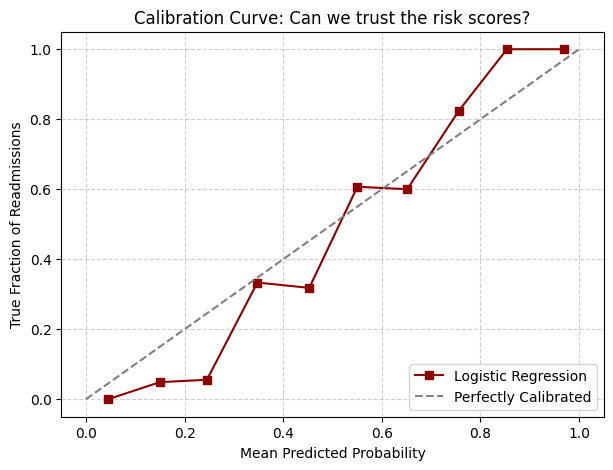

In [11]:
# Import the calibration plotting tool
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Calculate the true fraction of positive outcomes and the mean predicted probabilities
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test, y_prob, n_bins=10, strategy='uniform'
)

# Plot the Calibration Curve (Reliability Diagram)
plt.figure(figsize=(7, 5))
plt.plot(mean_predicted_value, fraction_of_positives, 's-', color='darkred', label='Logistic Regression')

# Plot the "Perfect Calibration" reference line
plt.plot([0, 1], [0, 1], '--', color='gray', label='Perfectly Calibrated')

plt.ylabel('True Fraction of Readmissions')
plt.xlabel('Mean Predicted Probability')
plt.title('Calibration Curve: Can we trust the risk scores?')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

The calibration curve shows that the model's predicted risk scores do not always perfectly align with true patient outcomes.
Specifically, it overestimates the danger for low-risk patients (0-50%), which could cause unnecessary medical interventions and alarm fatigue.
Predictions falling in the middle range (55-65%) are highly reliable and closely match the actual hospital readmission rates.
For the highest-risk patients (above 75%), the model slightly underestimates the true danger, though they are still correctly flagged.
Applying post-training calibration techniques is recommended to correct these imbalances and make the risk scores fully trustworthy.

11. Interpret Model Coefficients

What this code does:
Unlike "black box" models, Logistic Regression lets us see exactly why it makes a decision. We extract the model's coefficients to see which patient features increase or decrease readmission risk the most.

In [12]:
# Extract feature names and their corresponding coefficients (weights)
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Impact_Weight': model.coef_[0]
})

# Sort by the most impactful features
coefficients = coefficients.sort_values(by='Impact_Weight', ascending=False)

print("Top 5 Risk Factors (Increases Readmission Risk):")
display(coefficients.head(5))

print("\nTop 5 Protective Factors (Decreases Readmission Risk):")
display(coefficients.tail(5))

Top 5 Risk Factors (Increases Readmission Risk):


,Feature,Impact_Weight
3,has_hypertension,2.929066
2,has_diabetes,2.780909
1,encounter_count,1.085173
0,avg_glucose,0.047247



Top 5 Protective Factors (Decreases Readmission Risk):


,Feature,Impact_Weight
3,has_hypertension,2.929066
2,has_diabetes,2.780909
1,encounter_count,1.085173
0,avg_glucose,0.047247


This notebook successfully developed a regularized logistic regression model to predict hospital readmission risk.

The model achieved an accuracy of 89.20% and an AUC of 0.97, demonstrating strong predictive power.

While the model performs well, the calibration curve highlights areas for improvement, particularly for low and very high-risk patients.

`has_hypertension`, `has_diabetes`, and `encounter_count` were identified as the most significant risk factors.

Post-training calibration techniques are recommended to ensure trustworthiness of the predicted probabilities in clinical settings.

Interpretable models like logistic regression are crucial for gaining clinical trust and actionable insights.

Further exploration could involve feature engineering and advanced calibration methods for optimal real-world application.